In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
# split_type = 'simple'
split_type = 'mcquery'

In [4]:
# REMEMBER TO CHANGE CACHED DATAFRAMES PATH

file_type = 'zppresel'
# file_type = 'nuepresel'

In [5]:
import sys, os 
from data_loading import load_runs
from microfit.histogram import Binning, Histogram, RunHistGenerator

if file_type=='zppresel':
    RUN = ["4a_zppresel_75testsplit_75split", "4b_zppresel_75testsplit_75split", "4c_zppresel_75testsplit_75split", "4d_zppresel_75testsplit_75split", "5_zppresel_75testsplit_75split"]
    rundata, mc_weights, data_pot = load_runs(
        RUN,
        data="bnb",
        truth_filtered_sets=["nue", "drt", "nc_pi0"],
        use_truth_filters=False,
        loadpi0variables=True,
        loadshowervariables=True,
        loadrecoveryvars=True,
        loadsystematics=False,    # Set to false when we don't have event weights
        load_crt_vars=True,
        use_bdt = True,
        use_bdt_stacked=True,
        load_lee=False,
        enable_cache=True,
        blinded=True,
    )
if file_type=='nuepresel':
    RUN = ["4d_nuepresel_75testsplit_75split", "5_nuepresel_75testsplit_75split"]
    rundata, mc_weights, data_pot = load_runs(
        RUN,
        data="bnb",
        truth_filtered_sets=["nue", "drt", "nc_pi0"],
        use_truth_filters=False,
        loadpi0variables=True,
        loadshowervariables=True,
        loadrecoveryvars=True,
        loadsystematics=False,    # Set to false when we don't have event weights
        load_crt_vars=True,
        use_bdt = True,
        use_bdt_stacked=True,
        load_lee=False,
        enable_cache=True,
        blinded=True,
    )

Loading run 4a_zppresel_75testsplit_75split
Loading run 4b_zppresel_75testsplit_75split
Loading run 4c_zppresel_75testsplit_75split
Loading run 4d_zppresel_75testsplit_75split
Loading run 5_zppresel_75testsplit_75split


In [6]:
df_nu=rundata["mc"]
df_nue=rundata["nue"]
df_dirt=rundata["drt"]
df_ncpi0=rundata["nc_pi0"]
df_ext=rundata["ext"]

In [7]:
# import pandas as pd

# pd.set_option('display.max_rows', None)

# print(df_nue["category"])
# # print(df_nue["is_signal"])

In [8]:
# print(data_loading.py)

In [9]:
from sklearn.model_selection import train_test_split
import pandas as pd

# Split dataframes into training and testing samples
if split_type == 'simple':
    train_nu, test_nu = train_test_split(df_nu, test_size=0.5, random_state=1990)
    train_nue_truth, test_nue = train_test_split(df_nue, test_size=0.5, random_state=1990)
    train_dirt, test_dirt = train_test_split(df_dirt, test_size=0.5, random_state=1990)
    train_ncpi0_truth, test_ncpi0 = train_test_split(df_ncpi0, test_size=0.5, random_state=1990)
    train_ext, test_ext = train_test_split(df_ext, test_size=0.5, random_state=1990)

# if split_type == 'mcquery':
#     train_nue_truth, test_nue = train_test_split(df_nue, test_size=0.5, random_state=1990)
#     train_dirt, test_dirt = train_test_split(df_dirt, test_size=0.5, random_state=1990)
#     train_ncpi0_truth, test_ncpi0 = train_test_split(df_ncpi0, test_size=0.5, random_state=1990)
#     train_ext, test_ext = train_test_split(df_ext, test_size=0.5, random_state=1990)

if split_type == 'mcquery':
    train_nue_truth, test_nue = train_test_split(df_nue, test_size=0.75, random_state=1990)
    train_dirt, test_dirt = train_test_split(df_dirt, test_size=0.75, random_state=1990)
    train_ncpi0_truth, test_ncpi0 = train_test_split(df_ncpi0, test_size=0.75, random_state=1990)
    train_ext, test_ext = train_test_split(df_ext, test_size=0.75, random_state=1990)

In [10]:
if split_type == 'mcquery':
    # Separate CC Nue events from nu overlay
    NUEQUERY = '(abs(nu_pdg)==12 & ccnc==0)'
    nu_ccnue = df_nu.query(NUEQUERY)

    # Separate NC Pi0 events from nu overlay
    NCPI0QUERY = '(mcf_pass_ncpi0==1)'
    nu_ncpi0 = df_nu.query(NCPI0QUERY)

    # Get sample that doesn't have CC Nue or NC Pi0 events (basically take the opposite of the previous two queries combined)
    MCQUERY = '((abs(nu_pdg)==12 & ccnc==0) | mcf_pass_ncpi0==1)'
    nu_no_ccnue_ncpi0 = df_nu.query('~'+MCQUERY)

    # Split this new nu overlay sample into training and testing samples
    train_nu, test_nu = train_test_split(nu_no_ccnue_ncpi0, test_size=0.75, random_state=1990)

    # Add CC nue and NC pi0 events into their respective truth training samples
    train_nue = pd.concat([train_nue_truth, nu_ccnue], ignore_index=True)
    train_ncpi0 = pd.concat([train_ncpi0_truth, nu_ncpi0], ignore_index=True)

In [11]:
# second_split_type = 'simple'
second_split_type = 'nuequery'

In [12]:
if second_split_type == 'simple':
    train_nu_25p, test_nu_25p = train_test_split(test_nu, test_size = 0.5, random_state=1990)
    train_nue_25p, test_nue_25p = train_test_split(test_nue, test_size = 0.5, random_state=1990)
    train_dirt_25p, test_dirt_25p = train_test_split(test_dirt, test_size = 0.5, random_state=1990)
    train_ncpi0_25p, test_ncpi0_25p = train_test_split(test_ncpi0, test_size = 0.5, random_state=1990)
    train_ext_25p, test_ext_25p = train_test_split(test_ext, test_size = 0.5, random_state=1990)

# if second_split_type == 'nuequery':
#     train_nu_25p, test_nu_25p = train_test_split(test_nu, test_size = 0.5, random_state=1990)
#     train_dirt_25p, test_dirt_25p = train_test_split(test_dirt, test_size = 0.5, random_state=1990)
#     train_ncpi0_25p, test_ncpi0_25p = train_test_split(test_ncpi0, test_size = 0.5, random_state=1990)
#     train_ext_25p, test_ext_25p = train_test_split(test_ext, test_size = 0.5, random_state=1990)

if second_split_type == 'nuequery':
    train_nu_25p, test_nu_25p = train_test_split(test_nu, test_size = 0.75, random_state=1990)
    train_dirt_25p, test_dirt_25p = train_test_split(test_dirt, test_size = 0.75, random_state=1990)
    train_ncpi0_25p, test_ncpi0_25p = train_test_split(test_ncpi0, test_size = 0.75, random_state=1990)
    train_ext_25p, test_ext_25p = train_test_split(test_ext, test_size = 0.75, random_state=1990)

In [13]:
if second_split_type == 'nuequery':
    SIGNALQUERY = 'category == 10'
    BKGQUERY = 'category != 10'

    nue_signal = test_nue.query(SIGNALQUERY)
    nue_bkg = test_nue.query(BKGQUERY)

    train_nue_signal, test_nue_signal = train_test_split(nue_signal, test_size = 0.75, random_state=1990)
    train_nue_bkg, test_nue_bkg = train_test_split(nue_bkg, test_size = 0.75, random_state=1990)

    test_nue_25p = pd.concat([test_nue_signal, test_nue_bkg], ignore_index=True)

In [14]:
shr_kinematics = [
    # ("cos_shr_theta", 8, (-1, 1), "cos_shr_theta"),
    # ("cos_shr_theta", 20, (-1, 1), "cos_shr_theta"),
    # ("cos_shr_theta", 8, (-1, 0.5), "cos_shr_theta"),
    # ("cos_shr_theta", 8, (-1, 0.75), "cos_shr_theta"),
    ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.9, 1]),
    # ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.935, 1]),
    ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.94, 1]),
    ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.945, 1]),
    # ("cos_shr_theta", 2, (-1, 1), "cos_shr_theta", False, "Binning Label", [-1, 0.94, 1]),
    # ("cos_shr_theta", 1, (-1, 0.94), "cos_shr_theta"),
    # ("cos_shr_theta", 1, (0.94, 1), "cos_shr_theta"),
    # ("shr_energy_tot_cali", 20, (0, 4), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 10, (0, 1), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 4, (0, 1), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 2, (0, 4.5), "shr_energy_tot_cali", False, "Binning Label", [0, 0.65, 4.5]),
    # ("shr_energy_tot_cali", 1, (0, 0.65), "shr_energy_tot_cali"),
    # ("shr_energy_tot_cali", 1, (0.65, 4.5), "shr_energy_tot_cali"),
    # ("electron_e", 15, (0, 4.5), "electron_e"),
    # ("electron_e", 10, (0, 1), "electron_e"),
    # ("electron_e", 4, (0, 1), "electron_e"),
    # ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.9, 4.5]),
    # ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.95, 4.5]),
    ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.9, 4.5]),
    # ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.99, 4.5]),
    ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 1, 4.5]),
    ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 1.15, 4.5])
    # ("electron_e", 1, (0, 0.95), "electron_e"),
    # ("electron_e", 1, (0.95, 4.5), "electron_e"),
    # ("electron_e", 2, (0, 4.5), "electron_e", False, "Binning Label", [0, 0.9, 4.5]),
    # ("electron_e", 1, (0, 0.9), "electron_e"),
    # ("electron_e", 1, (0.9, 4.5), "electron_e"),
]

In [15]:
# varSet = crt_vars
# varSet = second_shr
# varSet = dedx_vars
# varSet = zp_variables_loose_bdt
# varSet = nugraph_vars
# varSet = slice_var
# varSet = slice_variables_slicecut
# varSet = bdt_vars
# varSet = proton_vars
# varSet = loosesel_variables_1eNp
# varSet = trksel_variables
# varSet = trkreco_vars
# varSet = trueproton_vars
# varSet = trk_true_reco
# varSet = bdt_2bdts_vars
# varSet = np_bdt_vars
varSet = shr_kinematics

In [16]:
zpquery = 'category == 10'
bkgquery = 'category != 10'

In [17]:
signal_test_nu_25p = test_nu_25p.query(zpquery)
signal_test_nue_25p = test_nue_25p.query(zpquery)
signal_test_dirt_25p = test_dirt_25p.query(zpquery)
signal_test_ncpi0_25p = test_ncpi0_25p.query(zpquery)
signal_test_ext_25p = test_ext_25p.query(zpquery)

In [18]:
rundata["mc"]=signal_test_nu_25p
rundata["nue"]=signal_test_nue_25p
rundata["drt"]=signal_test_dirt_25p
rundata["nc_pi0"]=signal_test_ncpi0_25p
rundata["ext"]=signal_test_ext_25p

/home/kate-pletcher/MicroBooNE/PELEE/microfit/histogram/run_hist_generator.py:163: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["dataset_name"] = k
/home/kate-pletcher/MicroBooNE/PELEE/microfit/histogram/run_hist_generator.py:164: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df["dataset_name"] = df["dataset_name"].astype("category")
/home/kate-pletcher/MicroBooNE/PELEE/microfit/run_plotter.py:132: UserWarning: No signal category found in the MC hists. Not separating signal.
  warnings.warn("No signal c

print_tot_pred_norm: [0.51586119 0.48413881]
print_tot_pred: [19.36406058 18.17328686]
print_tot_pred_norm: [0.6380809 0.3619191]
print_tot_pred: [23.95186458 13.58548287]
print_tot_pred_norm: [0.65700971 0.34299029]
print_tot_pred: [24.66240186 12.87494559]
print_tot_pred_norm: [0.60326359 0.39673641]
print_tot_pred: [22.63310116 14.88466311]
print_tot_pred_norm: [0.65216617 0.34783383]
print_tot_pred: [24.46781657 13.0499477 ]
print_tot_pred_norm: [0.72153207 0.27846793]
print_tot_pred: [27.07027015 10.44749412]


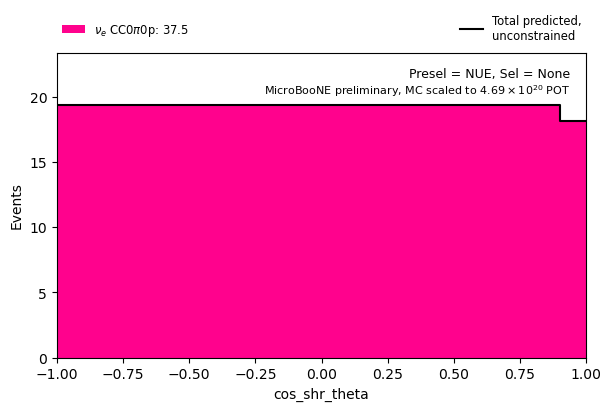

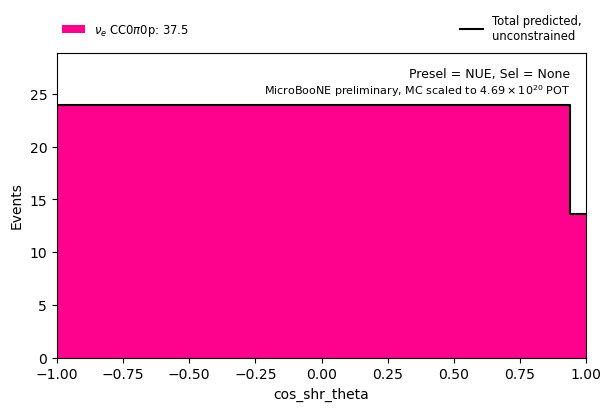

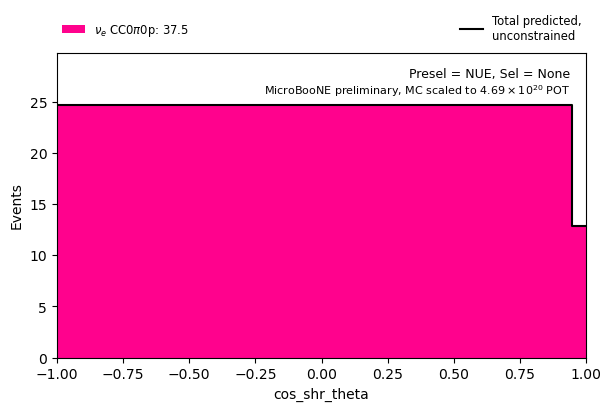

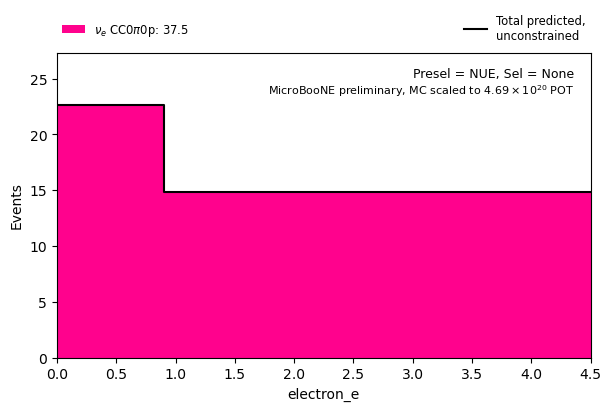

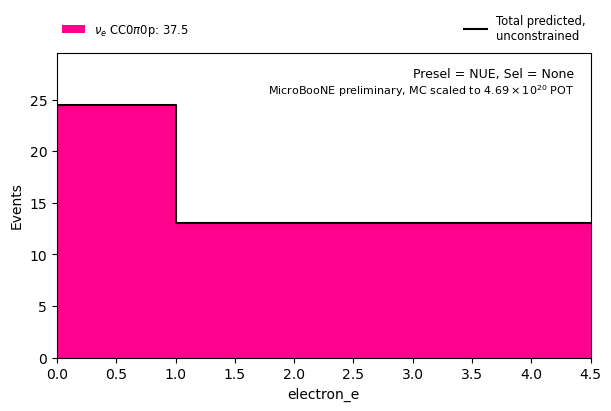

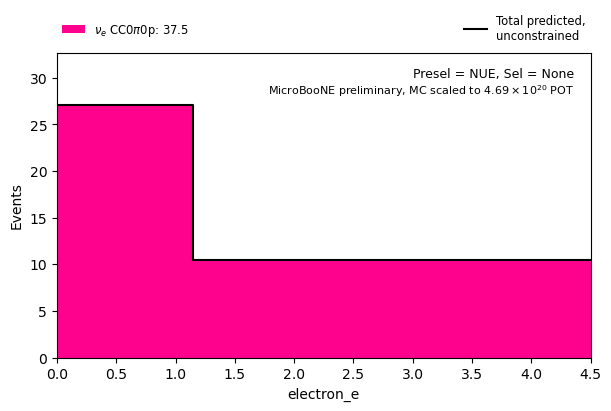

In [19]:
selection = 'None'
preselection = 'NUE'

rundata["mc"]=signal_test_nu_25p
rundata["nue"]=signal_test_nue_25p
rundata["drt"]=signal_test_dirt_25p
rundata["nc_pi0"]=signal_test_ncpi0_25p
rundata["ext"]=signal_test_ext_25p

for v in varSet:
    binning_def = v
    binning = Binning.from_config(*binning_def)
    binning.label = preselection
    binning.set_selection(selection, preselection)

    nuepresel_signal_generator = RunHistGenerator(
        rundata,
        binning,
        data_pot=data_pot,
    )

    from microfit.run_plotter import RunHistPlotter

    nuepresel_plotter = RunHistPlotter(nuepresel_signal_generator)
    
    # Blinded
    ax = nuepresel_plotter.plot(
        category_column="category",
        include_multisim_errors=False,
        add_ext_error_floor=False,
        show_data_mc_ratio=False,
        show_chi_square=False,
        show_total=False,           # Get rid of uncertainty
        title=f'Presel = {binning.preselection_key}, Sel = {binning.selection_key}',
        print_tot_pred_norm=True,
        scale_to_pot=4.69E20
    )

print_tot_pred_norm: [0.34474113 0.65525887]
print_tot_pred: [4.46013277 8.47749621]
print_tot_pred_norm: [0.49119102 0.50880898]
print_tot_pred: [6.3548472  6.58278178]
print_tot_pred_norm: [0.51666097 0.48333903]
print_tot_pred: [6.68436793 6.25326105]
print_tot_pred_norm: [0.44271266 0.55728734]
print_tot_pred: [5.72325329 7.20443948]
print_tot_pred_norm: [0.50218139 0.49781861]
print_tot_pred: [6.49204678 6.435646  ]
print_tot_pred_norm: [0.59947713 0.40052287]
print_tot_pred: [7.74985615 5.17783663]


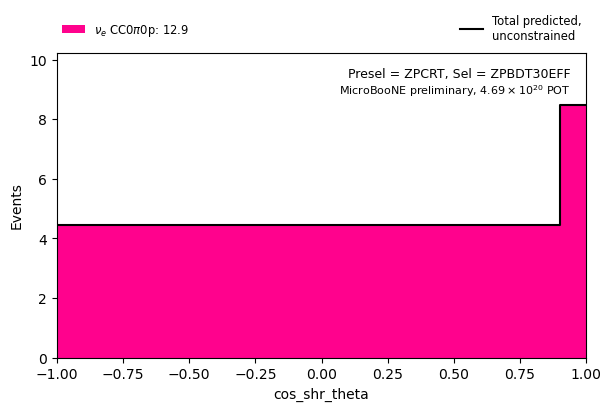

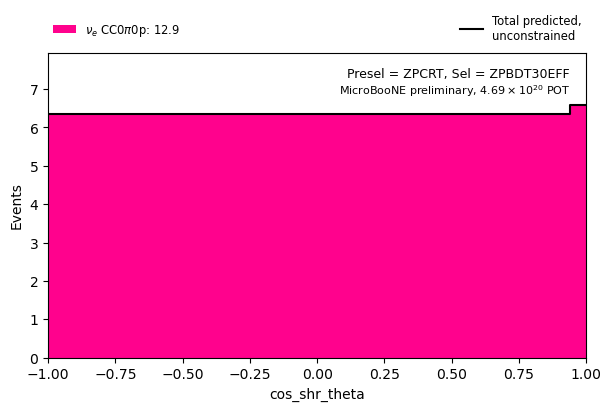

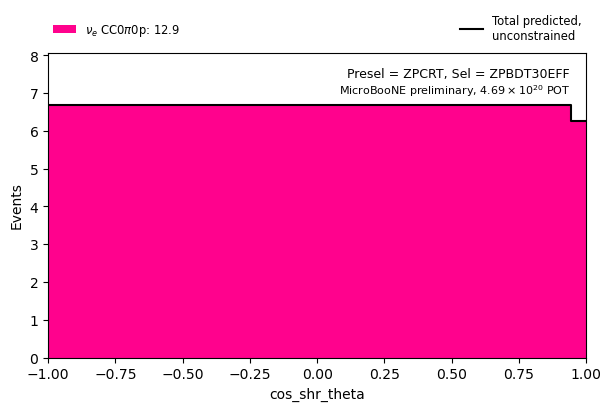

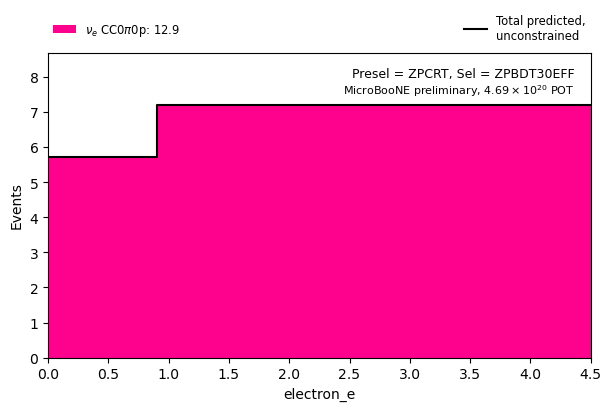

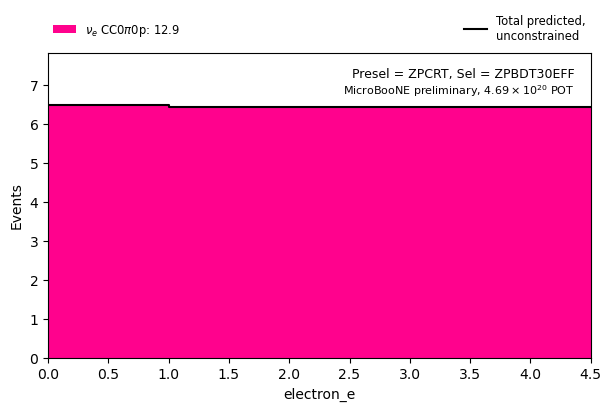

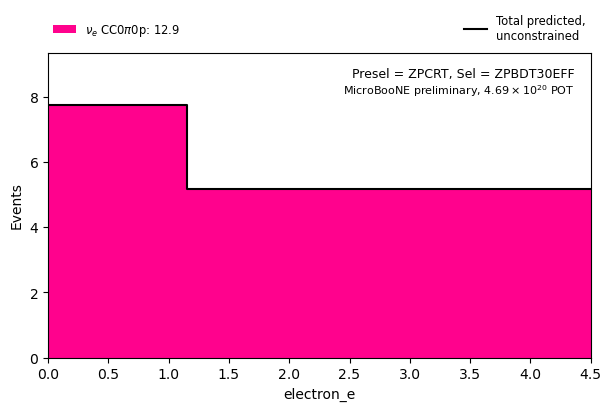

In [20]:
# preselection = 'NUE'
preselection = 'ZPCRT'

# selection = 'ZPBDT40EFF'
# selection = 'ZPBDT35EFF'
selection = 'ZPBDT30EFF'

for v in varSet:
    binning_def = v
    binning = Binning.from_config(*binning_def)
    binning.label = preselection
    binning.set_selection(selection, preselection)

    signal_signal_generator = RunHistGenerator(
        rundata,
        binning,
        data_pot=data_pot,
    )

    from microfit.run_plotter import RunHistPlotter

    signal_plotter = RunHistPlotter(signal_signal_generator)
    
    # Blinded
    ax = signal_plotter.plot(
        category_column="category",
        include_multisim_errors=False,
        add_ext_error_floor=False,
        show_data_mc_ratio=False,
        show_chi_square=False,
        show_total=False,           # Get rid of uncertainty
        title=f'Presel = {binning.preselection_key}, Sel = {binning.selection_key}',
        print_tot_pred_norm=True
    )

In [21]:
bkg_test_nu_25p = test_nu_25p.query(bkgquery)
bkg_test_nue_25p = test_nue_25p.query(bkgquery)
bkg_test_dirt_25p = test_dirt_25p.query(bkgquery)
bkg_test_ncpi0_25p = test_ncpi0_25p.query(bkgquery)
bkg_test_ext_25p = test_ext_25p.query(bkgquery)

rundata["mc"]=bkg_test_nu_25p
rundata["nue"]=bkg_test_nue_25p
rundata["drt"]=bkg_test_dirt_25p
rundata["nc_pi0"]=bkg_test_ncpi0_25p
rundata["ext"]=bkg_test_ext_25p

print_tot_pred_norm: [0.31534333 0.68465667]
print_tot_pred: [1.93016899 4.19068018]
print_tot_pred_norm: [0.48301143 0.51698857]
print_tot_pred: [2.95644011 3.16440905]
print_tot_pred_norm: [0.49116459 0.50883541]
print_tot_pred: [3.00634437 3.1145048 ]
print_tot_pred_norm: [0.51447537 0.48552463]
print_tot_pred: [3.14902613 2.97182303]
print_tot_pred_norm: [0.6468129 0.3531871]
print_tot_pred: [3.95904422 2.16180494]
print_tot_pred_norm: [0.70215196 0.29784804]
print_tot_pred: [4.29776624 1.82308292]


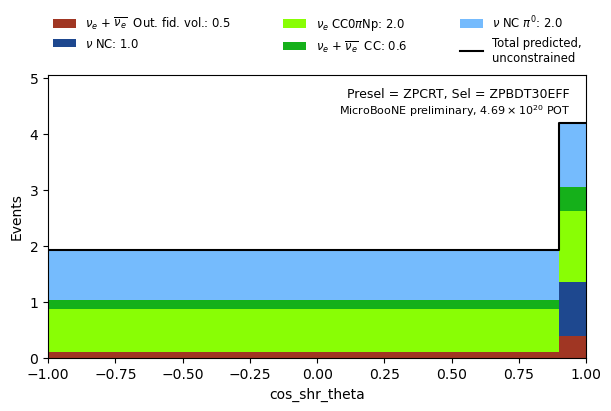

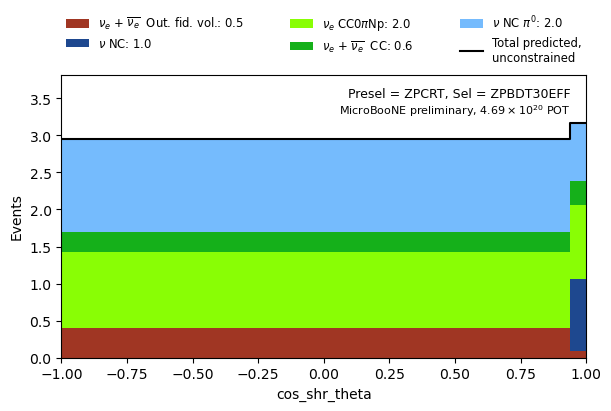

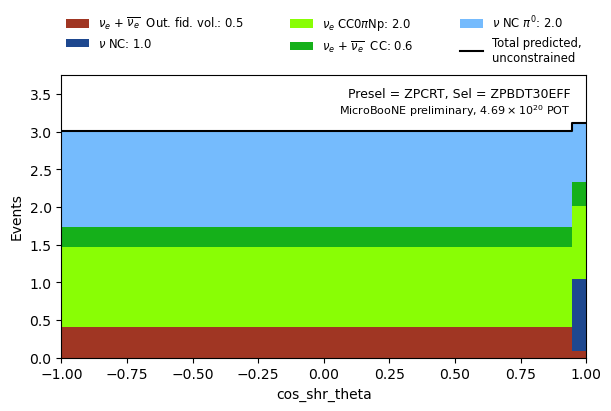

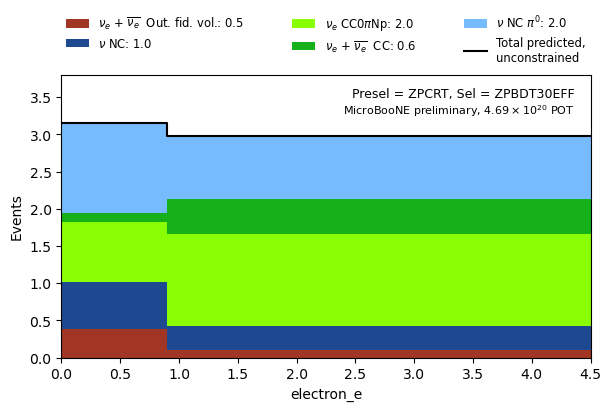

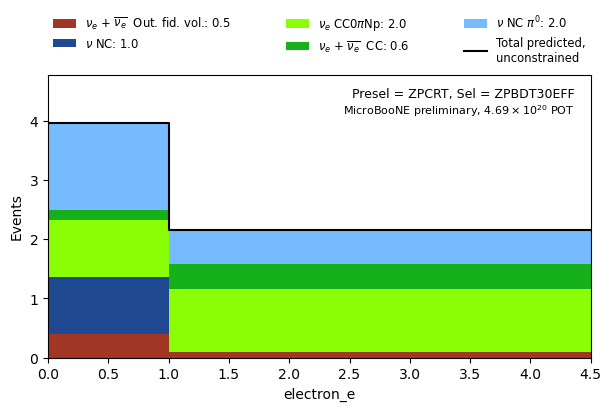

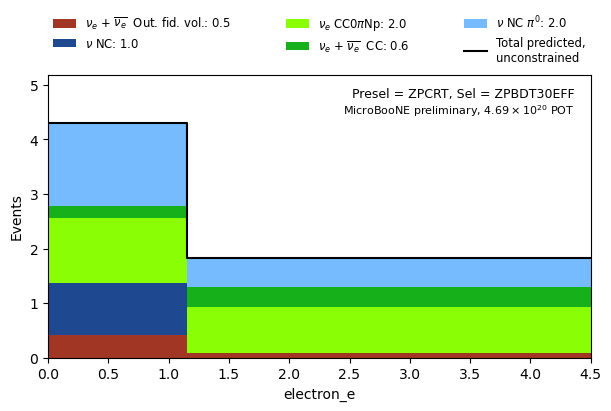

In [22]:
# preselection = 'NUE'
preselection = 'ZPCRT'

# selection = 'ZPBDT40EFF'
# selection = 'ZPBDT35EFF'
selection = 'ZPBDT30EFF'

for v in varSet:
    binning_def = v
    binning = Binning.from_config(*binning_def)
    binning.label = preselection
    binning.set_selection(selection, preselection)

    bkg_signal_generator = RunHistGenerator(
        rundata,
        binning,
        data_pot=data_pot,
    )
    
    from microfit.run_plotter import RunHistPlotter

    bkg_plotter = RunHistPlotter(bkg_signal_generator)
    
    # Blinded
    ax = bkg_plotter.plot(
        category_column="category",
        include_multisim_errors=False,
        add_ext_error_floor=False,
        show_data_mc_ratio=False,
        show_chi_square=False,
        show_total=False,           # Get rid of uncertainty
        title=f'Presel = {binning.preselection_key}, Sel = {binning.selection_key}',
        print_tot_pred_norm=True
    )

In [23]:
# import numpy as np

# # pur = np.divide(signal_signal_generator, np.add(signal_signal_generator,bkg_signal_generator))

# # pur = np.divide(signal_plotter, np.add(signal_plotter,bkg_plotter))

In [24]:
import numpy as np

if file_type == 'zppresel':
    shrangle_0_9_signal_pred_norm = [0.34474113, 0.65525887]
    shrangle_0_94_signal_pred_norm = [0.49119102, 0.50880898]
    shrangle_0_945_signal_pred_norm = [0.51666097, 0.48333903]

    shrE_0_9_signal_pred_norm = [0.44271266, 0.55728734]
    shrE_1_signal_pred_norm = [0.50218139, 0.49781861]
    shrE_1_15_signal_pred_norm = [0.59947713, 0.40052287]
    
    shrangle_0_9_signal_pred = [5.72325329, 7.20443948]
    shrangle_0_94_signal_pred = [6.49204678, 6.435646]
    shrangle_0_945_signal_pred = [7.74985615, 5.17783663]

    shrE_0_9_signal_pred = [5.72325329, 7.20443948]
    shrE_1_signal_pred = [6.49204678, 6.435646]
    shrE_1_15_signal_pred = [7.74985615, 5.17783663]

    shrangle_0_9_bkg_pred_norm = [0.31534333, 0.68465667]
    shrangle_0_94_bkg_pred_norm = [0.48301143, 0.51698857]
    shrangle_0_945_bkg_pred_norm = [0.49116459, 0.50883541]
    
    shrE_0_9_bkg_pred_norm = [0.51447537, 0.48552463]
    shrE_1_bkg_pred_norm = [0.6468129, 0.3531871]
    shrE_1_15_bkg_pred_norm = [0.70215196, 0.29784804]
    
    shrangle_0_9_bkg_pred = [1.93016899, 4.19068018]
    shrangle_0_94_bkg_pred = [2.95644011, 3.16440905]
    shrangle_0_945_bkg_pred = [3.00634437, 3.1145048 ]

    shrE_0_9_bkg_pred = [3.14902613, 2.97182303]
    shrE_1_bkg_pred = [3.95904422, 2.16180494]
    shrE_1_15_bkg_pred = [4.29776624, 1.82308292]
    
# Signal Prediction for Nue Preselection, scaled to full runs 4 and 5 POT (4.69E20)
shrangle_0_9_signal_pred_norm_nue = [0.52902304, 0.47097696]
shrangle_0_94_signal_pred_norm_nue = [0.6528833, 0.3471167]
shrangle_0_945_signal_pred_norm_nue = [0.6528833, 0.3471167]

shrE_0_9_signal_pred_norm_nue = [0.60742949, 0.39257051]
shrE_1_signal_pred_norm_nue = [0.63483597, 0.36516403]
shrE_1_15_signal_pred_norm_nue = [0.72502267, 0.27497733]

shrangle_0_9_signal_pred_nue = [22.51191758, 20.04183854]
shrangle_0_94_signal_pred_nue = [27.78263665, 14.77111947]
shrangle_0_945_signal_pred_nue = [27.78263665, 14.77111947]

shrE_0_9_signal_pred_nue = [25.83714164, 16.6980699]
shrE_1_signal_pred_nue = [27.00288218, 15.53232937]
shrE_1_15_signal_pred_nue = [30.83899277, 11.69621877]

In [25]:
shrangle_0_9_pur = np.divide(shrangle_0_9_signal_pred, np.add(shrangle_0_9_signal_pred, shrangle_0_9_bkg_pred))
shrangle_0_94_pur = np.divide(shrangle_0_94_signal_pred, np.add(shrangle_0_94_signal_pred, shrangle_0_94_bkg_pred))
shrangle_0_945_pur = np.divide(shrangle_0_945_signal_pred, np.add(shrangle_0_945_signal_pred, shrangle_0_945_bkg_pred))

shrE_0_9_pur = np.divide(shrE_0_9_signal_pred, np.add(shrE_0_9_signal_pred, shrE_0_9_bkg_pred))
shrE_1_pur = np.divide(shrE_1_signal_pred, np.add(shrE_1_signal_pred, shrE_1_bkg_pred))
shrE_1_15_pur = np.divide(shrE_1_15_signal_pred, np.add(shrE_1_15_signal_pred, shrE_1_15_bkg_pred))

shrangle_pur = [shrangle_0_9_pur, shrangle_0_94_pur, shrangle_0_945_pur]
shrE_pur = [shrE_0_9_pur, shrE_1_pur, shrE_1_15_pur]

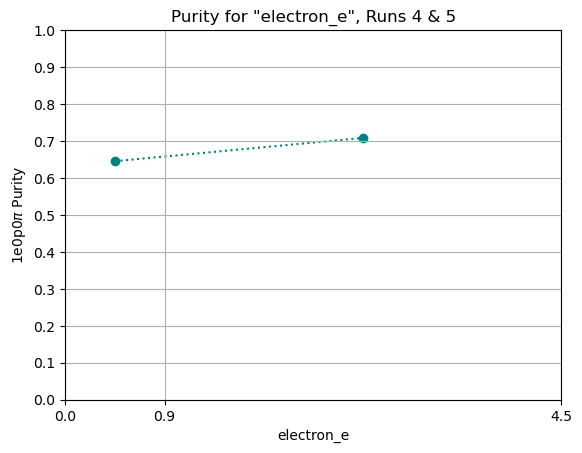

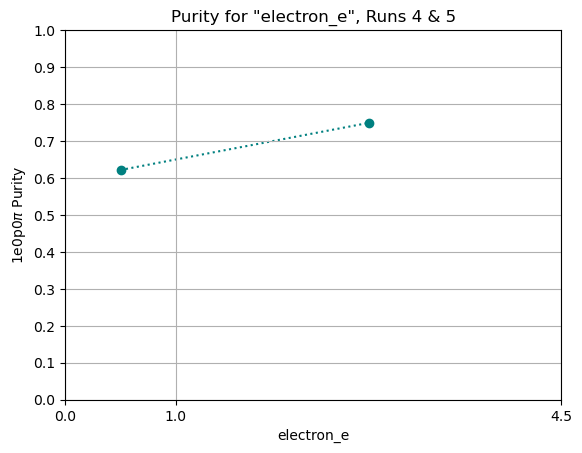

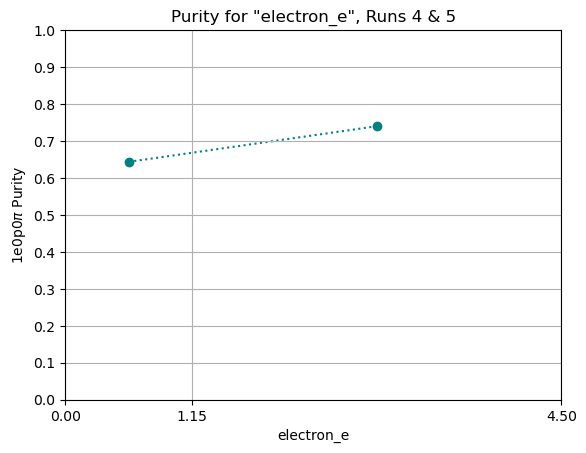

In [26]:
import matplotlib.pyplot as plt

shrE_split = [0.9, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_pur[i]

    plt.scatter(x, y, color='teal')
    plt.plot(x, y, linestyle=':', zorder=1, color='teal')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.ylabel(r"1e0p0$\pi$ Purity")
    if file_type == 'zppresel':
        plt.title('Purity for "electron_e", Runs 4 & 5')
    if file_type == 'nuepresel':
            plt.title('Purity for "electron_e", Runs 4d & 5')
    plt.show()

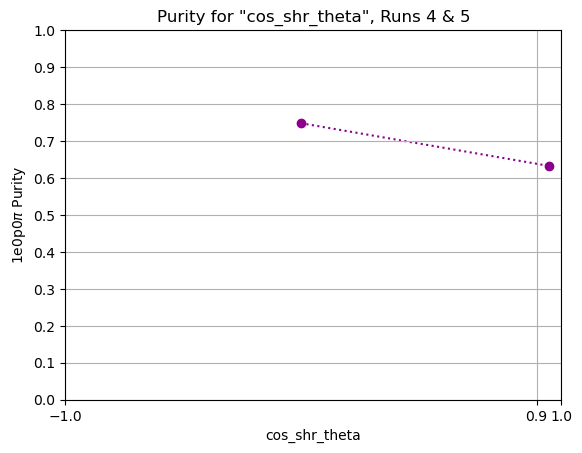

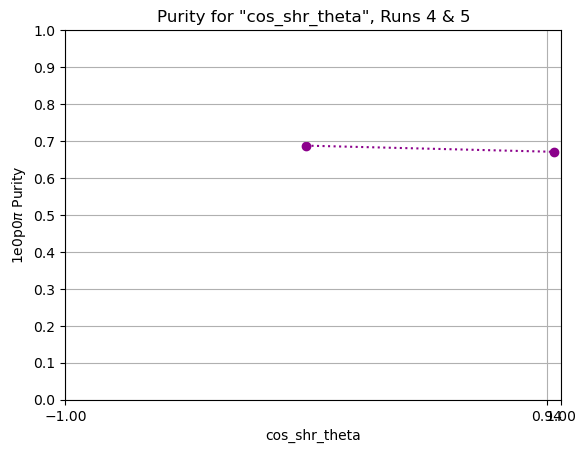

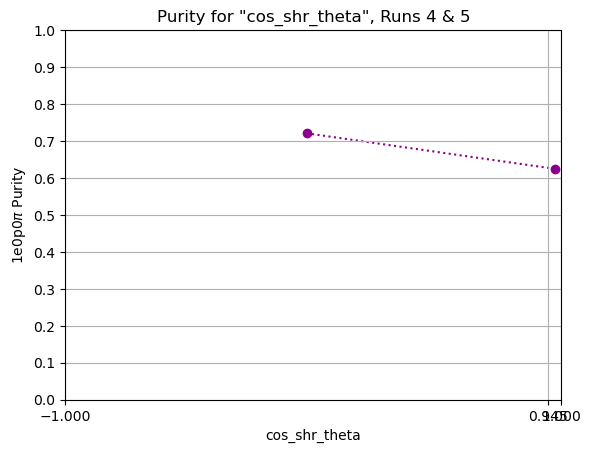

In [27]:
shrangle_split = [0.9, 0.94, 0.945]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_pur[i]

    plt.scatter(x, y, color='darkmagenta')
    plt.plot(x, y, linestyle=':', zorder=1, color='darkmagenta')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Purity")
    if file_type == 'zppresel':
        plt.title('Purity for "cos_shr_theta", Runs 4 & 5')
    if file_type == 'nuepresel':
        plt.title('Purity for "cos_shr_theta", Runs 4d & 5')
    plt.show()

In [28]:
shrE_0_9_eff = np.divide(shrE_0_9_signal_pred, shrE_0_9_signal_pred_nue)
shrE_1_eff = np.divide(shrE_1_signal_pred, shrE_1_signal_pred_nue)
shrE_1_15_eff = np.divide(shrE_1_15_signal_pred, shrE_1_15_signal_pred_nue)

shrangle_0_9_eff = np.divide(shrangle_0_9_signal_pred, shrangle_0_9_signal_pred_nue)
shrangle_0_94_eff = np.divide(shrangle_0_94_signal_pred, shrangle_0_94_signal_pred_nue)
shrangle_0_945_eff = np.divide(shrangle_0_945_signal_pred, shrangle_0_945_signal_pred_nue)

shrE_eff = [shrE_0_9_eff, shrE_1_eff, shrE_1_15_eff]
shrangle_eff = [shrangle_0_9_eff, shrangle_0_94_eff, shrangle_0_945_eff]

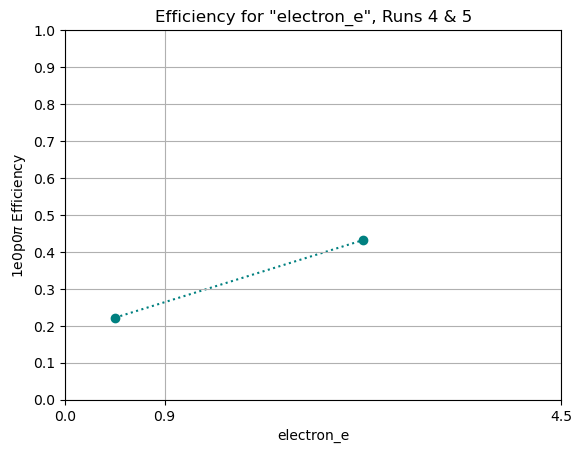

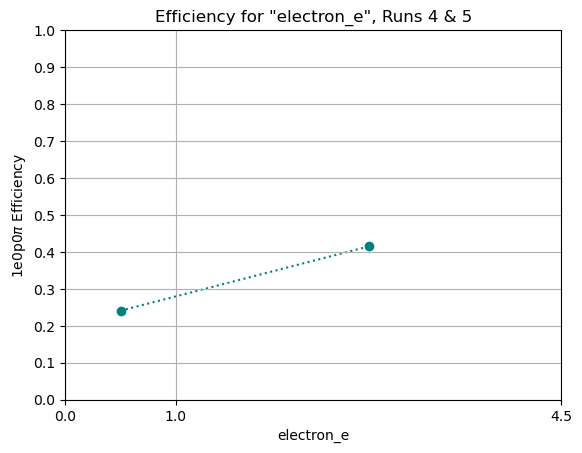

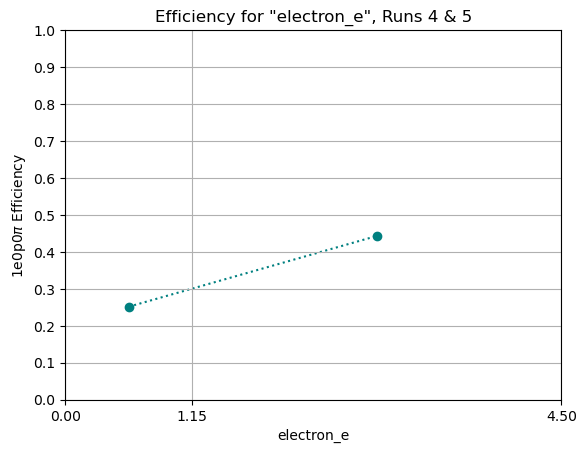

In [29]:
# shrE_split = [0.9, 0.95, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_eff[i]

    plt.scatter(x, y, color='teal')
    plt.plot(x, y, linestyle=':', zorder=1, color='teal')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.ylabel(r"1e0p0$\pi$ Efficiency")
    if file_type == 'zppresel':
        plt.title('Efficiency for "electron_e", Runs 4 & 5')
    if file_type == 'nuepresel':
            plt.title('Efficiency for "electron_e", Runs 4d & 5')
    plt.show()

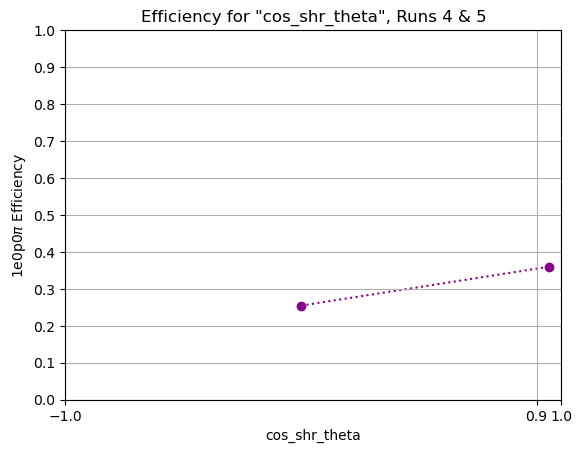

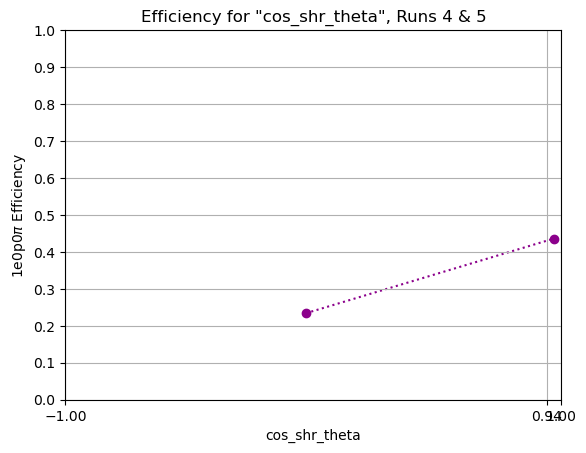

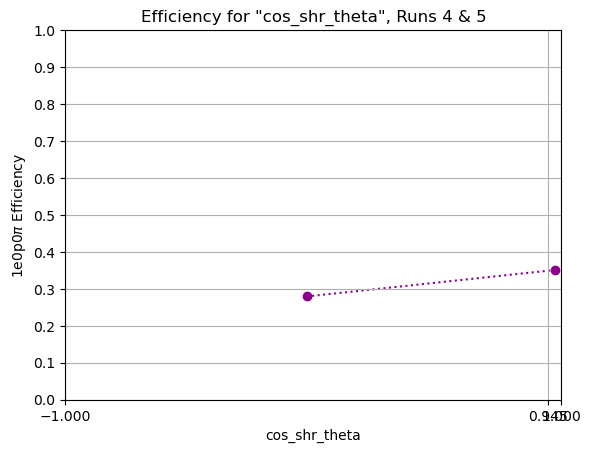

In [30]:
# shrangle_split = [0.9, 0.935, 0.94]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_eff[i]

    plt.scatter(x, y, color='darkmagenta')
    plt.plot(x, y, linestyle=':', zorder=1, color='darkmagenta')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Efficiency")
    if file_type == 'zppresel':
        plt.title('Efficiency for "cos_shr_theta", Runs 4 & 5')
    if file_type == 'nuepresel':
        plt.title('Efficiency for "cos_shr_theta", Runs 4d & 5')
    plt.show()

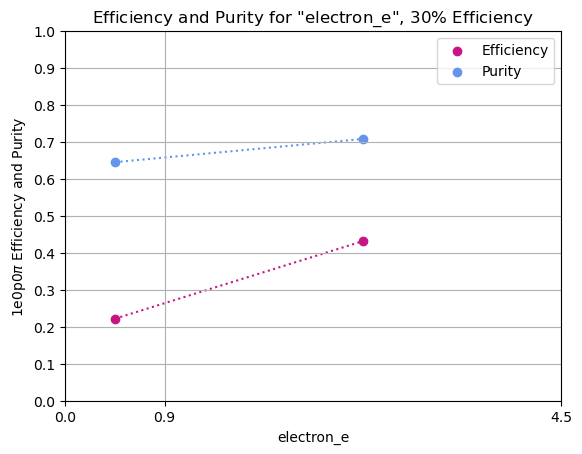

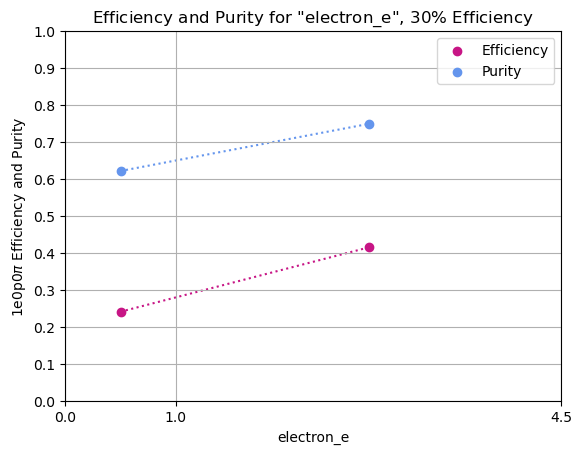

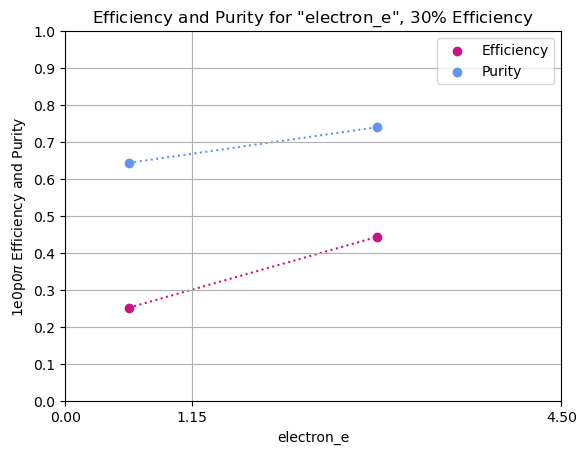

In [31]:
# shrE_split = [0.9, 0.95, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_eff[i]
    y2 = shrE_pur[i]

    plt.scatter(x, y, color='mediumvioletred', label='Efficiency')
    plt.scatter(x, y2, color='cornflowerblue', label='Purity')
    plt.plot(x, y, linestyle=':', zorder=1, color='mediumvioletred')
    plt.plot(x, y2, linestyle=':', zorder=1, color='cornflowerblue')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.legend()
    plt.ylabel(r"1e0p0$\pi$ Efficiency and Purity")
    if file_type == 'zppresel':
        plt.title(r'Efficiency and Purity for "electron_e", 30$\%$ Efficiency')
    if file_type == 'nuepresel':
            plt.title(r'Efficiency and Purity for "electron_e", 30$\%$ Efficiency')
    plt.show()

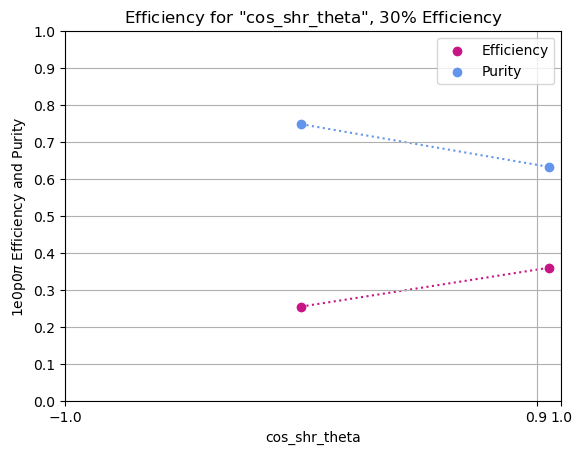

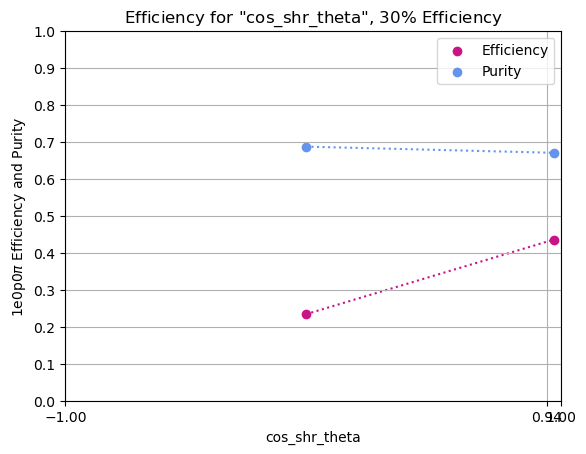

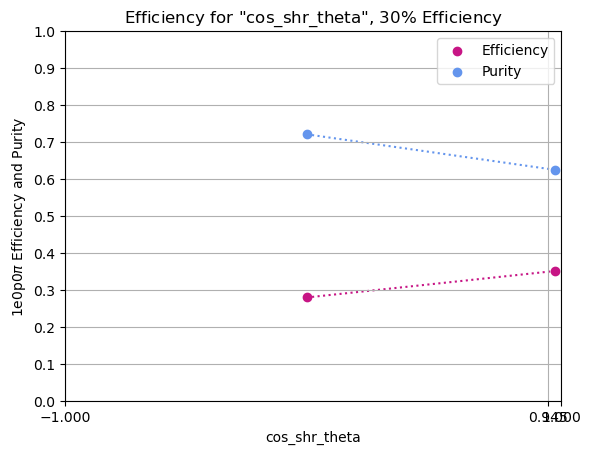

In [32]:
# shrangle_split = [0.9, 0.935, 0.94]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_eff[i]
    y2 = shrangle_pur[i]

    plt.scatter(x, y, color='mediumvioletred', label='Efficiency')
    plt.scatter(x, y2, color='cornflowerblue', label='Purity')
    plt.plot(x, y, linestyle=':', zorder=1, color='mediumvioletred')
    plt.plot(x, y2, linestyle=':', zorder=1, color='cornflowerblue')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Efficiency and Purity")
    plt.legend()
    if file_type == 'zppresel':
        plt.title(r'Efficiency for "cos_shr_theta", 30$\%$ Efficiency')
    if file_type == 'nuepresel':
        plt.title(r'Efficiency for "cos_shr_theta", 30$\%$ Efficiency')
    plt.show()

In [33]:
shrangle_effxpur_0_9 = np.multiply(shrangle_0_9_pur, shrangle_0_9_eff)
shrangle_effxpur_0_94 = np.multiply(shrangle_0_94_pur, shrangle_0_94_eff)
shrangle_effxpur_0_945 = np.multiply(shrangle_0_945_pur, shrangle_0_945_eff)

shrE_effxpur_0_9 = np.multiply(shrE_0_9_pur, shrE_0_9_eff)
shrE_effxpur_1 = np.multiply(shrE_1_pur, shrE_1_eff)
shrE_effxpur_1_15 = np.multiply(shrE_1_15_pur, shrE_1_15_eff)

shrangle_effxpur = [shrangle_effxpur_0_9, shrangle_effxpur_0_94, shrangle_effxpur_0_945]
shrE_effxpur = [shrE_effxpur_0_9, shrE_effxpur_1, shrE_effxpur_1_15]

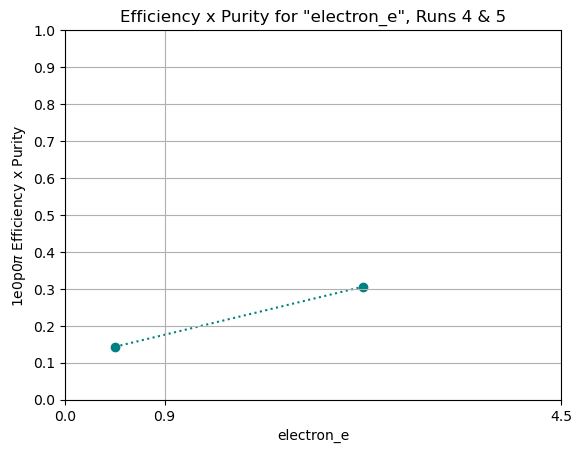

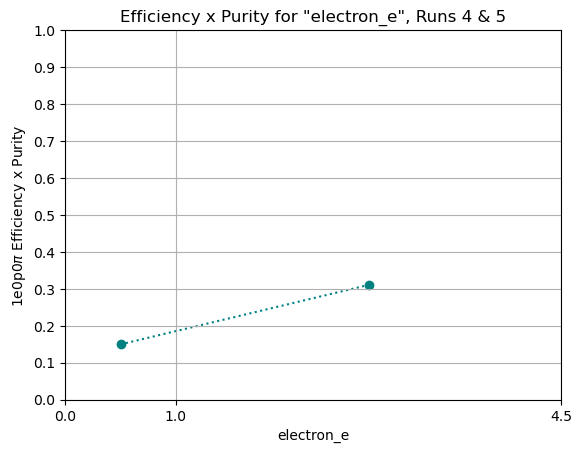

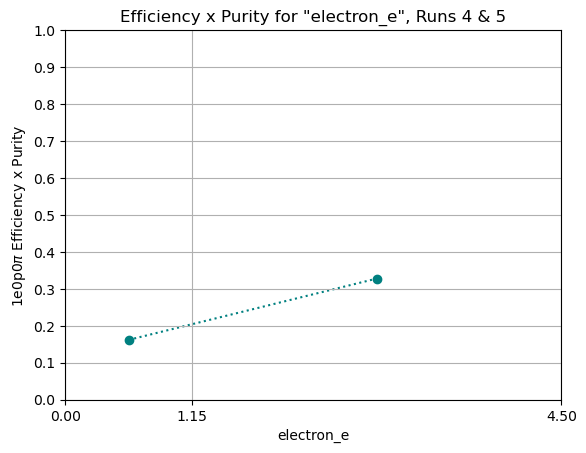

In [34]:
# shrE_split = [0.9, 0.95, 1, 1.15]
shrE_max = 4.5

for i in range(len(shrE_split)):
    x = (shrE_split[i]/2, (shrE_max+shrE_split[i])/2)
    y = shrE_effxpur[i]

    plt.scatter(x, y, color='teal')
    plt.plot(x, y, linestyle=':', zorder=1, color='teal')
    plt.xlim(0, 4.5)
    plt.ylim(0, 1)
    plt.xticks([0, shrE_split[i], 4.5])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('electron_e')
    plt.ylabel(r"1e0p0$\pi$ Efficiency x Purity")
    if file_type == 'zppresel':
        plt.title('Efficiency x Purity for "electron_e", Runs 4 & 5')
    if file_type == 'nuepresel':
            plt.title('Efficiency x Purity for "electron_e", Runs 4d & 5')
    plt.show()

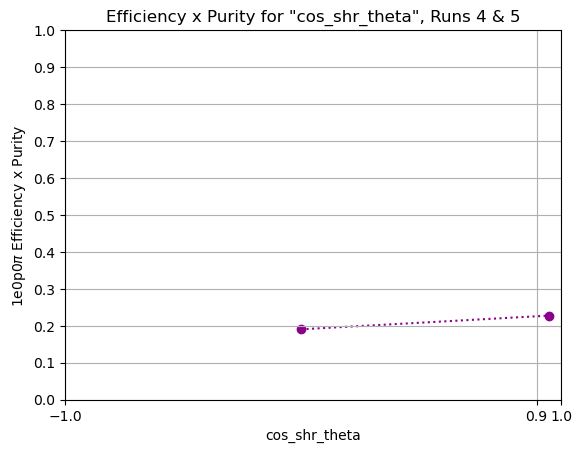

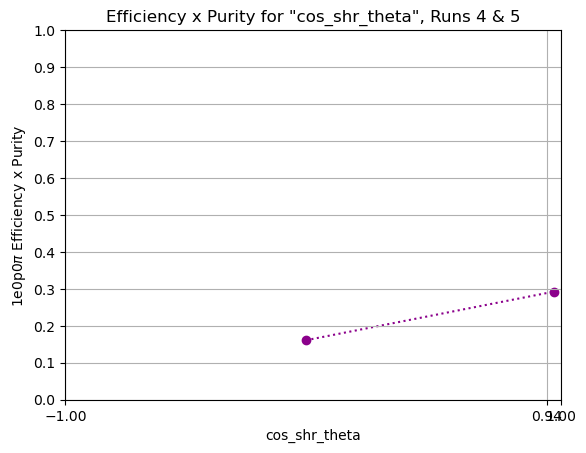

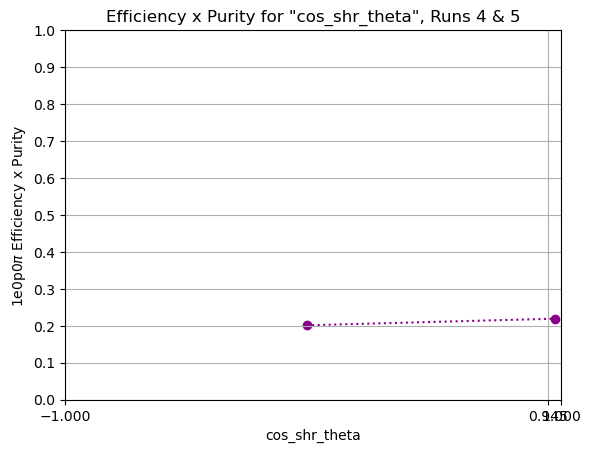

In [35]:
# shrangle_split = [0.9, 0.935, 0.94]
shrangle_max = 1
shrangle_min = -1

for i in range(len(shrangle_split)):
    x = ((shrangle_split[i]+shrangle_min)/2, (shrangle_max+shrangle_split[i])/2)
    y = shrangle_effxpur[i]

    plt.scatter(x, y, color='darkmagenta')
    plt.plot(x, y, linestyle=':', zorder=1, color='darkmagenta')
    plt.xlim(-1, 1)
    plt.ylim(0, 1)
    plt.xticks([-1, shrangle_split[i], 1])
    plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
    plt.grid(True)
    plt.xlabel('cos_shr_theta')
    plt.ylabel(r"1e0p0$\pi$ Efficiency x Purity")
    if file_type == 'zppresel':
        plt.title('Efficiency x Purity for "cos_shr_theta", Runs 4 & 5')
    if file_type == 'nuepresel':
        plt.title('Efficiency x Purity for "cos_shr_theta", Runs 4d & 5')
    plt.show()